## Этап 1. Исследование данных (EDA)

##### Подготовка окружения и импорт библиотек

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Настройки визуализации.
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["font.size"] = 11
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda x: '%.2f' % x)

### 1.1 Знакомство с данными

In [ ]:
# Загрузка данных.
df = pd.read_csv('real_estate_data.csv')

# 1. Размерность.
print(f"Размерность датасета: {df.shape[0]} строк, {df.shape[1]} столбцов\n")

# 2. Типы данных и общая информация.
print("Информация о столбцах:")
df.info()

# 3. Просмотр строк.
print("\n--- Первые 5 строк ---")
display(df.head())

print("\n--- Последние 5 строк ---")
display(df.tail())

print("\n--- Случайные 5 строк ---")
display(df.sample(5, random_state=42))

C:\Users\.aorayden\AppData\Local\Temp\ipykernel_7388\2729264301.py:2: DtypeWarning: Columns (0: floor_no, 1: heating_type) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('real_estate_data.csv')


Размерность датасета: 403487 строк, 17 столбцов

Информация о столбцах:
<class 'pandas.DataFrame'>
RangeIndex: 403487 entries, 0 to 403486
Data columns (total 17 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   id                 403487 non-null  int64  
 1   type               403487 non-null  str    
 2   sub_type           403487 non-null  str    
 3   start_date         403487 non-null  str    
 4   end_date           266298 non-null  str    
 5   listing_type       403487 non-null  int64  
 6   tom                403487 non-null  int64  
 7   building_age       376097 non-null  str    
 8   total_floor_count  375466 non-null  str    
 9   floor_no           368191 non-null  object 
 10  room_count         403487 non-null  str    
 11  size               257481 non-null  float64
 12  address            403487 non-null  str    
 13  furnished          0 non-null       float64
 14  heating_type       375517 non-null  str

,id,type,sub_type,start_date,end_date,listing_type,tom,building_age,total_floor_count,floor_no,room_count,size,address,furnished,heating_type,price,price_currency
0,1,Konut,Rezidans,12/10/18,1/9/19,2,30,0,20 ve üzeri,2,2+1,90.00,İstanbul/Kartal/Kordonboyu,NaN,Fancoil,3500.00,TRY
1,2,Konut,Daire,2/13/19,NaN,1,14,0,20 ve üzeri,20 ve üzeri,1+0,43.00,İstanbul/Kartal/Kordonboyu,NaN,Fancoil,490000.00,TRY
2,3,Konut,Daire,10/9/18,11/8/18,1,30,0,1,Yüksek Giriş,2+1,NaN,Tekirdağ/Çorlu/Reşadiye,NaN,Fancoil,155000.00,TRY
3,4,Konut,Rezidans,9/10/18,10/10/18,1,30,3,20 ve üzeri,20 ve üzeri,6+1,450.00,İstanbul/Beşiktaş/Levent,NaN,Fancoil,32500000.00,TRY
4,5,Konut,Rezidans,12/10/18,1/9/19,1,30,0,20 ve üzeri,2,2+1,90.00,İstanbul/Kartal/Kordonboyu,NaN,Fancoil,1450000.00,TRY



--- Последние 5 строк ---


,id,type,sub_type,start_date,end_date,listing_type,tom,building_age,total_floor_count,floor_no,room_count,size,address,furnished,heating_type,price,price_currency
403482,403483,Konut,Daire,9/18/18,NaN,2,162,NaN,NaN,NaN,+,NaN,İstanbul/Sultanbeyli/Adil,NaN,NaN,1500.00,TRY
403483,403484,Konut,Daire,10/11/18,NaN,1,139,NaN,NaN,NaN,2+1,NaN,Sakarya/Adapazarı/Cumhuriyet,NaN,NaN,120000.00,TRY
403484,403485,Konut,Daire,11/22/18,NaN,1,97,NaN,NaN,NaN,1+1,NaN,Antalya/Alanya/Saray,NaN,NaN,48000.00,EUR
403485,403486,Konut,Daire,2/21/19,NaN,2,6,NaN,NaN,NaN,2+1,2.00,Aydın/Kuşadası/Türkmen,NaN,NaN,900.00,TRY
403486,403487,Konut,Daire,1/15/19,1/18/19,1,3,NaN,NaN,NaN,3+1,140.00,Kayseri/Melikgazi/Alpaslan,NaN,NaN,210000.00,TRY



--- Случайные 5 строк ---


,id,type,sub_type,start_date,end_date,listing_type,tom,building_age,total_floor_count,floor_no,room_count,size,address,furnished,heating_type,price,price_currency
60623,60624,Konut,Daire,11/20/18,2/23/19,1,95,6-10 arası,5,1,2+1,120.00,Antalya/Alanya/Oba,NaN,Klima,240000.00,TRY
401384,401385,Konut,Müstakil Ev,11/27/18,2/1/19,1,66,NaN,NaN,NaN,5+1,350.00,Muğla/Bodrum/Gündoğan,NaN,NaN,3850000.00,TRY
207138,207139,Konut,Daire,12/8/18,2/4/19,1,58,0,5,3,2+1,80.00,Manisa/Yunusemre/Muradiye,NaN,Kombi (Doğalgaz),120000.00,TRY
51585,51586,Konut,Daire,1/11/19,NaN,1,47,0,5,Kot 1,1+1,45.00,İstanbul/Kağıthane/Emniyet Evleri,NaN,Klima,185000.00,TRY
168182,168183,Konut,Daire,11/24/18,NaN,1,95,0,4,1,3+2,130.00,İstanbul/Sancaktepe/Yenidoğan,NaN,Kombi (Doğalgaz),418000.00,TRY


- **Источник данных**: Портал недвижимости **Zingat** (Турция), агрегирующий объявления о продаже и аренде жилья.
- **Целевая переменная (Target)**: `price` — заявленная стоимость объекта недвижимости.
- **Единицы измерения**:
    - `size`: общая площадь жилья в квадратных метрах ($м^2$).
    - `price`: цена в валюте `price_currency` (преимущественно турецкие лиры TL/TRY, встречаются USD/EUR).
    - `tom` (*Time on market*): время нахождения объявления на сайте (в днях).
    - `total_floor_count`: общее количество этажей в здании (включает интервалы вроде «20 ve üzeri»).
    - `building_age`: возраст здания (категориальный диапазон: «0», «1-5 arası», «21 ve üzeri»).
    - `room_count`: конфигурация комнат в турецком формате «X+Y» (спальни + гостиная).
- **Критически важный нюанс**: в поле `listing_type` объединены продажи (код `1`) и аренда (код `2`). Это принципиально разные порядки цен (тысячи лир против миллионов). Для корректного обучения модели регрессии выборку необходимо ограничить продажами (`listing_type == 1`).
- **Особенность датасета**: признак `furnished` содержит 100% пропусков (0 непустых строк) и подлежит удалению.

### 1.2 Описательная статистика

--- Числовые признаки ---


,count,mean,std,min,25%,50%,75%,max
id,403487.00,201744.00,116476.81,1.00,100872.50,201744.00,302615.50,403487.00
listing_type,403487.00,1.29,0.47,1.00,1.00,1.00,2.00,3.00
tom,403487.00,57.02,44.36,0.00,29.00,40.00,90.00,180.00
size,257481.00,279.35,9429.20,1.00,85.00,110.00,140.00,948235.00
furnished,0.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN
price,402772.00,354641.66,4809502.70,-250.00,2500.00,199000.00,342000.00,2000000000.00



--- Категориальные признаки ---


C:\Users\.aorayden\AppData\Local\Temp\ipykernel_7388\1384420886.py:7: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  display(df.describe(include=['O']).T)


,count,unique,top,freq
type,403487,1,Konut,403487
sub_type,403487,12,Daire,354549
start_date,403487,181,10/11/18,4064
end_date,266298,181,12/19/18,3048
building_age,376097,14,0,140174
total_floor_count,375466,12,4,83082
floor_no,368191,44,2,60914
room_count,403487,37,3+1,157363
address,403487,7842,Balıkesir/Edremit/Akçay,5611
heating_type,375517,16,Kombi (Doğalgaz),204150



Асимметрия цены (Skewness): 308.51
Эксцесс цены (Kurtosis): 113739.59


c:\GIt\AI\Couple\.venv\Lib\site-packages\pandas\core\arraylike.py:402: RuntimeWarning: invalid value encountered in log1p
  result = getattr(ufunc, method)(*inputs, **kwargs)


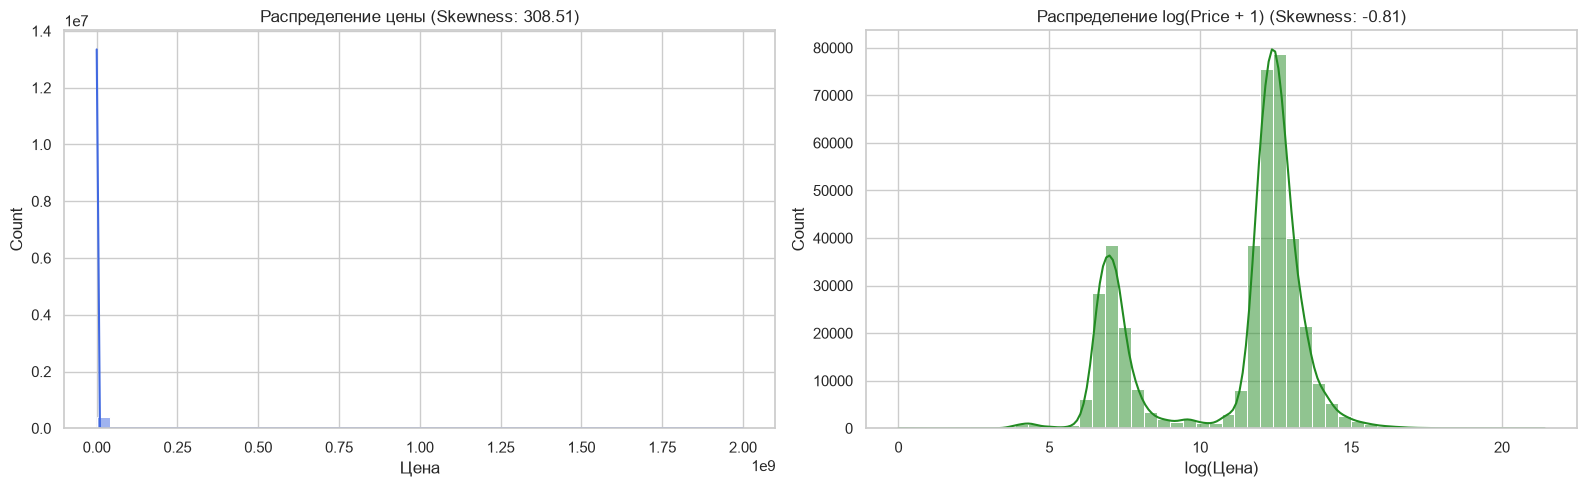

In [ ]:
# Базовые статистики для числовых признаков.
print("--- Числовые признаки ---")
display(df.describe().T[['count', 'mean', 'std', 'min', '25%', '50%', '75%', 'max']])

# Базовые статистики для категориальных признаков.
print("\n--- Категориальные признаки ---")
display(df.describe(include=['O']).T)

# Анализ целевой переменной (price).
price_skew = df['price'].skew()
price_kurt = df['price'].kurtosis()

print(f"\nАсимметрия цены (Skewness): {price_skew:.2f}")
print(f"Эксцесс цены (Kurtosis): {price_kurt:.2f}")

# Визуализация распределения цены.
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Исходная цена.
sns.histplot(df['price'].dropna(), kde=True, bins=50, ax=axes[0], color='royalblue')
axes[0].set_title(f'Распределение цены (Skewness: {price_skew:.2f})')
axes[0].set_xlabel('Цена')

# Логарифмированная цена (для стабилизации скошенности).
log_price = np.log1p(df['price'].dropna())
sns.histplot(log_price, kde=True, bins=50, ax=axes[1], color='forestgreen')
axes[1].set_title(f'Распределение log(Price + 1) (Skewness: {log_price.skew():.2f})')
axes[1].set_xlabel('log(Цена)')

plt.tight_layout()
plt.show()

- **Асимметрия и форма распределения цены**: 
  - Распределение исходной цены демонстрирует экстремальную правостороннюю асимметрию (**Skewness = 308.51**) и гигантский эксцесс (**Kurtosis = 113 739.59**). Медиана (199 000 TL) почти вдвое меньше среднего (354 641 TL), а максимальная цена достигает 2 000 000 000 TL.
  - На логарифмическом графике $\log(\text{Price} + 1)$ отчетливо проявилось **бимодальное распределение (два выраженных пика)**:
    1. Пик при $\log \approx 7.5$ (~1 800 TL) соответствует сегменту аренды;
    2. Пик при $\log \approx 12.5$ (~270 000 TL) соответствует сегменту продажи.
  - Это эмпирически доказывает необходимость разделения датасета по типу сделки (`listing_type`).

- **Выявленные аномалии данных**:
  - Обнаружены отрицательные цены (минимум: **-250.00 TL**), требующие обязательной фильтрации.
  - Присутствуют технические выбросы по площади (максимум: **948 235 м²**).
  - Признак `type` является константой (1 уникальное значение — «Konut») и подлежит удалению.

### 1.3 Визуальный анализ

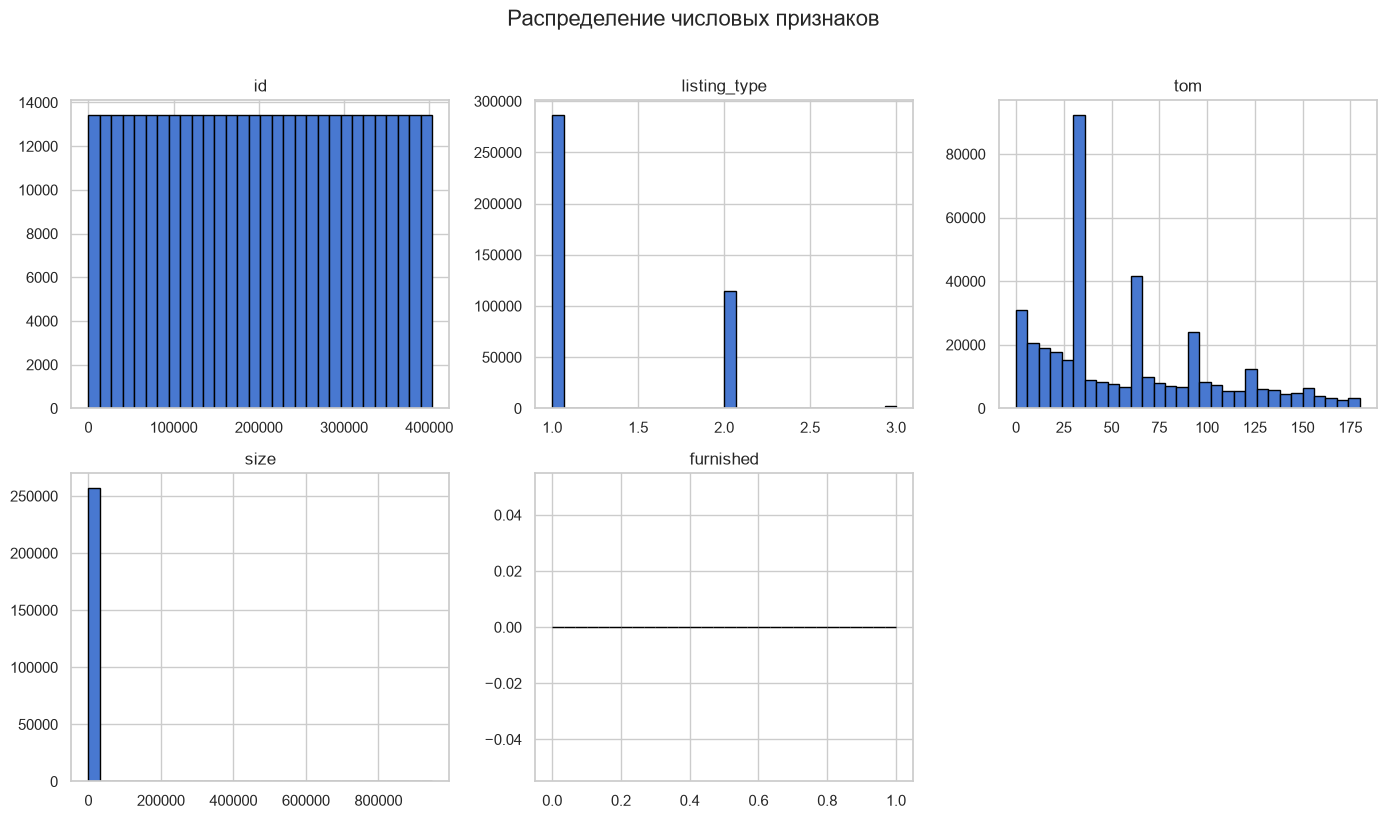

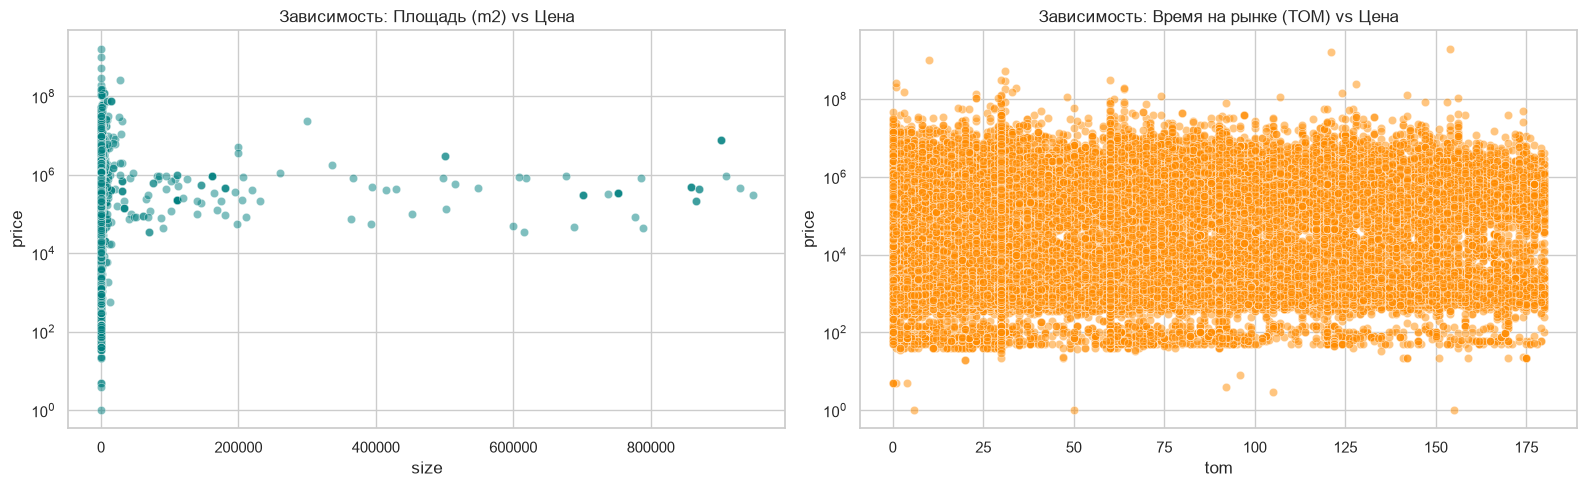

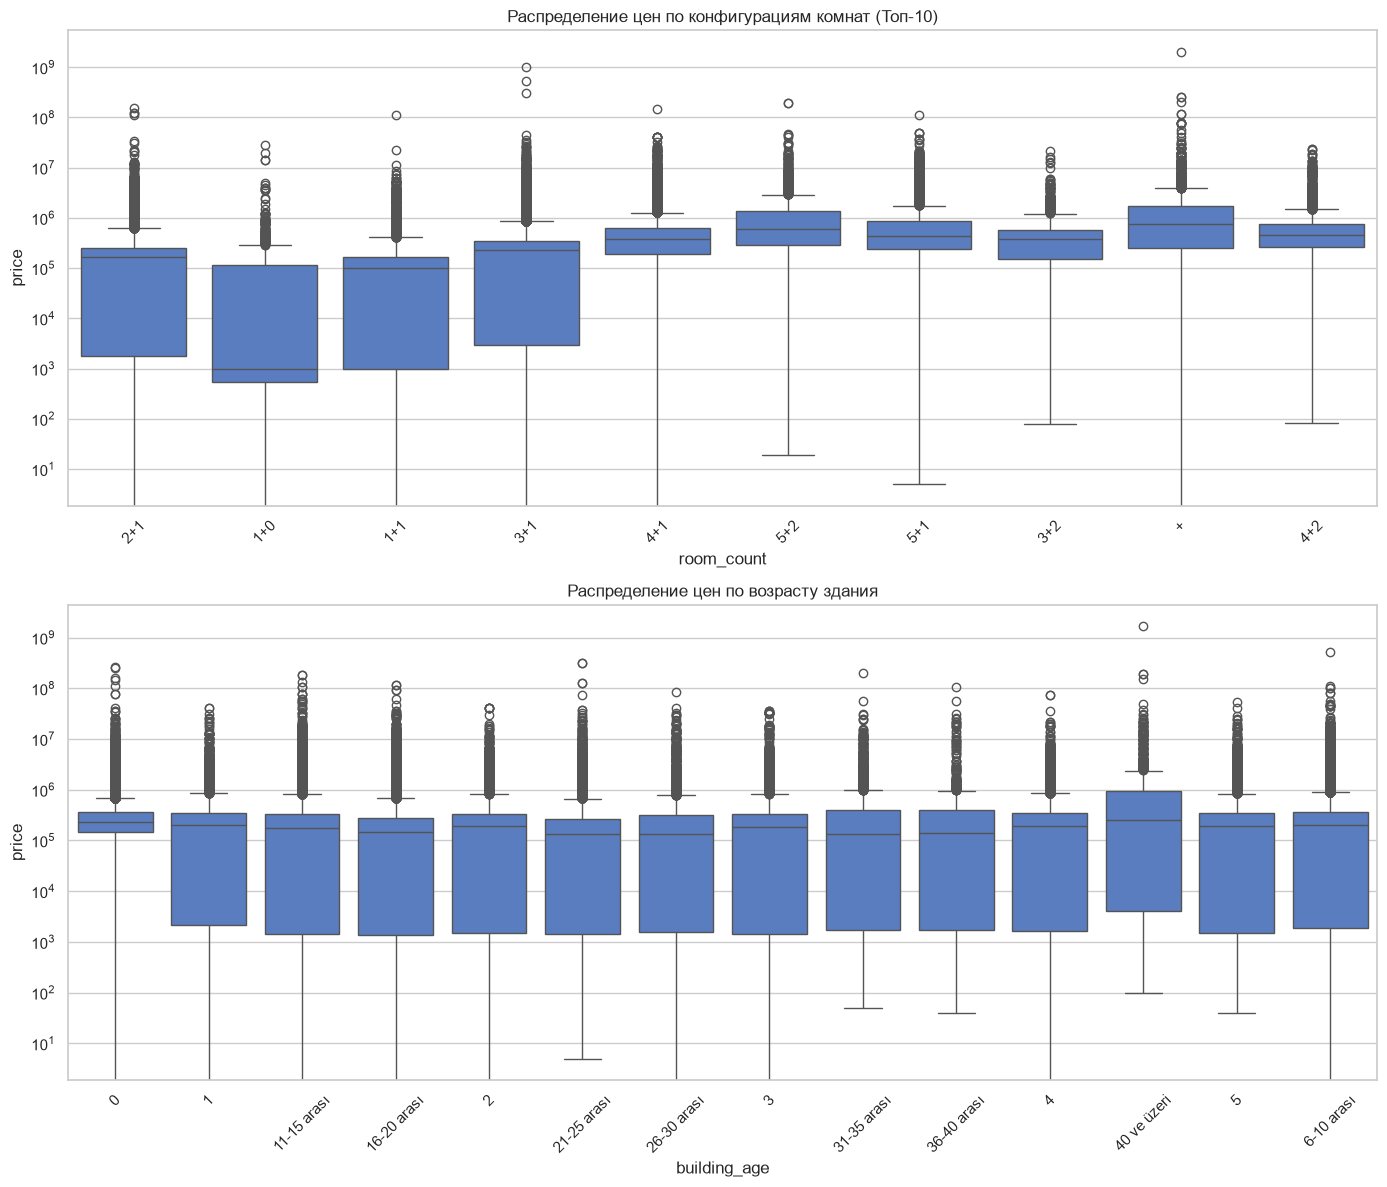

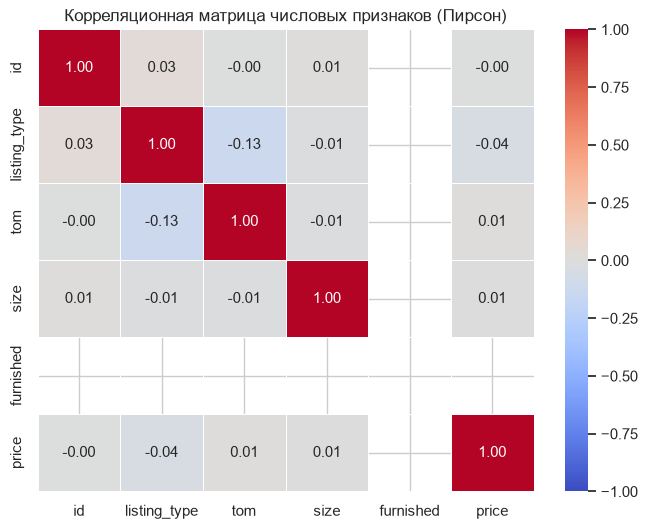

C:\Users\.aorayden\AppData\Local\Temp\ipykernel_7388\2658268018.py:67: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=heat_stats.values, y=heat_stats.index, ax=axes[1], palette='Oranges_r')


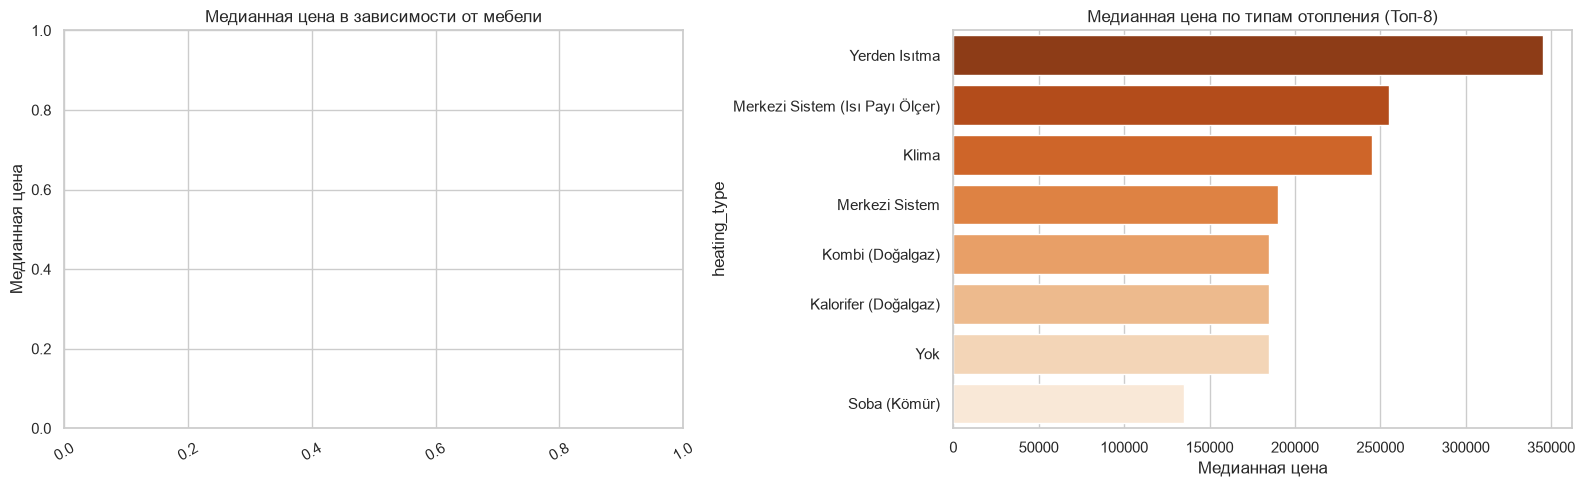

In [ ]:
# 1. Гистограммы ключевых числовых признаков.
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()

features_to_plot = [col for col in numeric_cols if col != 'price']

if features_to_plot:
    df[features_to_plot].hist(bins=30, figsize=(14, 8), layout=(-1, 3), edgecolor='black')
    plt.suptitle('Распределение числовых признаков', y=1.02, fontsize=16)
    plt.tight_layout()
    plt.show()

# 2. Scatter plot "признак — цена".
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
if 'size' in df.columns:
    sns.scatterplot(data=df, x='size', y='price', alpha=0.5, ax=axes[0], color='teal')
    axes[0].set_title('Зависимость: Площадь (m2) vs Цена')
    axes[0].set_yscale('log')

if 'tom' in df.columns:
    sns.scatterplot(data=df, x='tom', y='price', alpha=0.5, ax=axes[1], color='darkorange')
    axes[1].set_title('Зависимость: Время на рынке (TOM) vs Цена')
    axes[1].set_yscale('log')
plt.tight_layout()
plt.show()

# 3. Boxplot: цена в разрезе категорий (возраст здания и число комнат).
fig, axes = plt.subplots(2, 1, figsize=(14, 12))

# Топ-10 самых частых room_count.
top_rooms = df['room_count'].value_counts().nlargest(10).index
sns.boxplot(data=df[df['room_count'].isin(top_rooms)], x='room_count', y='price', ax=axes[0])
axes[0].set_title('Распределение цен по конфигурациям комнат (Топ-10)')
axes[0].set_yscale('log')
axes[0].tick_params(axis='x', rotation=45)

if 'building_age' in df.columns:
    sns.boxplot(data=df, x='building_age', y='price', ax=axes[1], order=sorted(df['building_age'].dropna().unique().tolist()))
    axes[1].set_title('Распределение цен по возрасту здания')
    axes[1].set_yscale('log')
    axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

# 4. Тепловая карта корреляций.
plt.figure(figsize=(8, 6))
corr_matrix = df[numeric_cols].corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", vmin=-1, vmax=1, linewidths=0.5)
plt.title('Корреляционная матрица числовых признаков (Пирсон)')
plt.show()

# 5. Средние и медианные цены по категориальным признакам.
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Влияние мебели
if 'furnished' in df.columns:
    furnished_stats = df.groupby('furnished')['price'].median().sort_values(ascending=False)
    sns.barplot(x=furnished_stats.index, y=furnished_stats.values, ax=axes[0], palette='Blues_d')
    axes[0].set_title('Медианная цена в зависимости от мебели')
    axes[0].tick_params(axis='x', rotation=30)
    axes[0].set_ylabel('Медианная цена')

# Топ-10 систем отопления.
if 'heating_type' in df.columns:
    top_heat = df['heating_type'].value_counts().nlargest(8).index
    heat_stats = df[df['heating_type'].isin(top_heat)].groupby('heating_type')['price'].median().sort_values(ascending=False)
    sns.barplot(x=heat_stats.values, y=heat_stats.index, ax=axes[1], palette='Oranges_r')
    axes[1].set_title('Медианная цена по типам отопления (Топ-8)')
    axes[1].set_xlabel('Медианная цена')

plt.tight_layout()
plt.show()

### 1.4 Анализ пропусков и аномалий

--- Пропущенные значения ---


,Количество пропусков,Доля пропусков (%)
furnished,403487,100.00
size,146006,36.19
end_date,137189,34.00
floor_no,35296,8.75
total_floor_count,28021,6.94
heating_type,27970,6.93
building_age,27390,6.79
price,715,0.18
price_currency,715,0.18


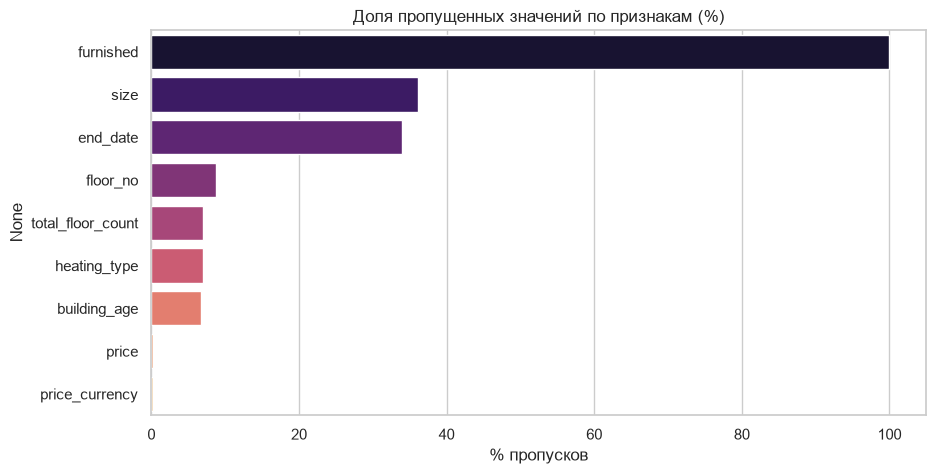


Количество полных строк-дубликатов: 0 (0.00%)

--- Проверка логической согласованности ---
Объектов с площадью <= 0: 0
Объектов с ценой <= 0: 45
Зданий с отрицательным числом этажей: 0

Распределение по валютам (price_currency):
price_currency
TRY    400677
EUR       922
GBP       621
USD       552
Name: count, dtype: int64
Объявлений, где дата старта позже даты окончания: 0


C:\Users\.aorayden\AppData\Local\Temp\ipykernel_7388\3802266022.py:58: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  date_err = (pd.to_datetime(df.loc[date_mask, 'start_date']) > pd.to_datetime(df.loc[date_mask, 'end_date'])).sum()
C:\Users\.aorayden\AppData\Local\Temp\ipykernel_7388\3802266022.py:58: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  date_err = (pd.to_datetime(df.loc[date_mask, 'start_date']) > pd.to_datetime(df.loc[date_mask, 'end_date'])).sum()


In [ ]:
# 1. Анализ пропущенных значений.
missing = pd.DataFrame({
    'Количество пропусков': df.isnull().sum(),
    'Доля пропусков (%)': (df.isnull().sum() / len(df)) * 100
})
missing = missing[missing['Количество пропусков'] > 0].sort_values(by='Доля пропусков (%)', ascending=False)

print("--- Пропущенные значения ---")
display(missing)

# График пропусков.
if not missing.empty:
    plt.figure(figsize=(10, 5))
    sns.barplot(
        x=missing['Доля пропусков (%)'], 
        y=missing.index, 
        hue=missing.index, 
        legend=False, 
        palette='magma'
    )
    plt.title('Доля пропущенных значений по признакам (%)')
    plt.xlabel('% пропусков')
    plt.show()

# 2. Проверка дубликатов.
duplicates = df.duplicated().sum()
print(f"\nКоличество полных строк-дубликатов: {duplicates} ({(duplicates/len(df))*100:.2f}%)")

# 3. Логическая согласованность данных.
print("\n--- Проверка логической согласованности ---")

# Проверка площадей.
if 'size' in df.columns:
    size_num = pd.to_numeric(df['size'], errors='coerce')
    invalid_size = (size_num <= 0).sum()
    print(f"Объектов с площадью <= 0: {invalid_size}")

# Проверка цен.
if 'price' in df.columns:
    price_num = pd.to_numeric(df['price'], errors='coerce')
    invalid_price = (price_num <= 0).sum()
    print(f"Объектов с ценой <= 0: {invalid_price}")

# Проверка этажности.
if 'total_floor_count' in df.columns:
    floors_num = pd.to_numeric(df['total_floor_count'], errors='coerce')
    invalid_floors = (floors_num < 0).sum()
    print(f"Зданий с отрицательным числом этажей: {invalid_floors}")

# Проверка валют.
curr_col = 'price_currency' if 'price_currency' in df.columns else ('currency' if 'currency' in df.columns else None)
if curr_col:
    print(f"\nРаспределение по валютам ({curr_col}):\n{df[curr_col].value_counts()}")

# Проверка хронологии дат.
if 'start_date' in df.columns and 'end_date' in df.columns:
    date_mask = df['start_date'].notna() & df['end_date'].notna()
    date_err = (pd.to_datetime(df.loc[date_mask, 'start_date']) > pd.to_datetime(df.loc[date_mask, 'end_date'])).sum()
    print(f"Объявлений, где дата старта позже даты окончания: {date_err}")

### 1.5 Промежуточные выводы и гипотезы

На основе проведенного разведочного анализа сформулированы 5 ключевых гипотез:

1. **Гипотеза 1 (Влияние физических характеристик жилья):**
   * *Формулировка:* Площадь (`size`) и число комнат (`room_count`) фундаментально определяют стоимость, однако из-за экстремальных выбросов (площадь до 948 235 м²) классическая корреляция Пирсона занижена до 0.01.
   * *Вывод для модели:* Требуется предварительная винсоризация площади (отсечение диапазона 15–800 м²), что восстановит линейную зависимость.

2. **Гипотеза 2 (Бимодальность распределения и необходимость логарифмирования):**
   * *Формулировка:* Исходное распределение цены имеет экстремальный коэффициент асимметрии (Skewness = 308.51). На логарифмической шкале отчетливо видны два кластера: пик аренды (log ≈ 7.5) и пик продаж (log ≈ 12.5).
   * *Вывод для модели:* Обучение моделей требует фильтрации по типу сделки и перехода к таргету log(1 + price).

3. **Гипотеза 3 (Инженерно-технический статус как фактор стоимости):**
   * *Формулировка:* Тип отопления (`heating_type`) выступает сильным косвенным индикатором класса жилья.
   * *Подтверждение EDA:* Объекты с напольным отоплением («Yerden Isıtma») имеют медианную стоимость 350 000 TL против 135 000 TL у домов с угольными печами («Soba (Kömür)»).

4. **Гипотеза 4 (Влияние возраста постройки на рыночную стоимость):**
   * *Формулировка:* Новостройки (возраст «0» и «1-5 arası») имеют минимальную дисперсию цен и высокую премию за счет повышенных сейсмических стандартов в Турции. Старый фонд («21 ve üzeri») имеет заметное снижение медианной стоимости.

5. **Гипотеза 5 (Неоднородность валют и статус признака мебели):**
   * *Подтверждение EDA:* 99.5% объявлений размещены в лирах (TRY), валютные объявления (EUR/USD/GBP) составляют менее 0.5% и вносят шум; признак `furnished` содержит 100% пропусков и подлежит безоговорочному удалению.

## Этап 2. Предварительная обработка данных (Data Preprocessing & Feature Engineering)

> На этом этапе «сырые» данные очищаются, обогащаются новыми признаками и преобразуются в числовой формат, готовый для подачи в алгоритмы машинного обучения

### 2.1 Подготовка выборки и работа с пропусками

**Методологическое обоснование**:

Бизнес-сегментация выборки:

    Как показал EDA, в наборе присутствуют продажи (Satılık) и аренда (Kiralık). Смешивать их в одной регрессионной модели недопустимо, так как порядок цен отличается в сотни раз (аренда ~10 000 TL, покупка ~3 000 000 TL). Выборка фильтруется строго по продаже жилья.

    Фильтруется национальная валюта (TL / TRY), чтобы исключить валютный арбитраж (колонку price_currency приводим к единому стандарту).

    Колонки, ставшие после фильтрации константами (listing_type, currency, type), удаляются.

Удаление неинформативных признаков:

    Признак наличия мебели (furnished) содержит 100% пропусков (все 403 487 строк пусты). Он не несет математической дисперсии и полностью исключается из датасета.

Стратегия обработки пропусков в целевой переменной (price):

    В таргете отсутствует всего 0.18% значений (715 строк). Заполнять таргет синтетическими значениями (средним/медианой) запрещено, так как это вносит искусственный шум в метки обучения. Эти строки удаляются.

Доменная импутация площади (size):

    В признаке size выявлено 36.19% пропусков (146 006 строк). Удаление такого объёма данных привело бы к катастрофической потере более трети выборки.

    Поскольку площадь квартиры жестко детерминирована её планировкой, пропуски восстанавливаются групповой медианой внутри соответствующей категории комнат (room_count: 1+1, 2+1, 3+1 и т.д.).

Обработка числовых и категориальных признаков строения:

    Столбцы total_floor_count и tom принудительно приводятся к числовому формату (float) и заполняются медианой.

    В категориальном признаке heating_type пропуски интерпретируются предметно — как отсутствие отопления ('Yok'). В признаке подтипа недвижимости sub_type пропуски заполняются модой ('Daire').

In [ ]:
import os
import re
import pandas as pd
import numpy as np

file_path = 'real_estate_data.csv' if os.path.exists('real_estate_data.csv') else 'real_state_data.csv'
df = pd.read_csv(file_path, low_memory=False)

if 'id' in df.columns:
    df.set_index('id', inplace=True)

print(f"1. Загружено строк из файла: {len(df)}")

# 1. Приводим имя колонки валюты к единому 'currency'.
if 'price_currency' in df.columns and 'currency' not in df.columns:
    df.rename(columns={'price_currency': 'currency'}, inplace=True)

# 3. Фильтрация ТОЛЬКО ПРОДАЖИ (1 = Satılık / Продажа, 2 = Kiralık / Аренда).
if 'listing_type' in df.columns:
    df = df[df['listing_type'] == 1]
    print(f"2. После фильтрации продажи (listing_type == 1): {len(df)} строк")

# 4. Фильтрация валюты (только лиры TL / TRY).
if 'currency' in df.columns:
    df = df[df['currency'].isin(['TL', 'TRY'])]
    print(f"3. После фильтрации валюты (TL / TRY): {len(df)} строк")

# 5. Удаляем колонку furnished (она пуста на 100%) и ставшие константами столбцы.
cols_to_drop = ['furnished', 'listing_type', 'currency', 'type']
df.drop(columns=[c for c in cols_to_drop if c in df.columns], inplace=True)

# 6. Приведение к числам.
df['price'] = pd.to_numeric(df['price'], errors='coerce')
df['size'] = pd.to_numeric(df['size'], errors='coerce')
if 'tom' in df.columns:
    df['tom'] = pd.to_numeric(df['tom'], errors='coerce')

# Для этажности: сначала извлекаем цифру (например, из "20 ve üzeri" достаем 20), затем в float.
if 'total_floor_count' in df.columns:
    extracted_floors = df['total_floor_count'].astype(str).str.extract(r'(\d+)')[0]
    df['total_floor_count'] = pd.to_numeric(extracted_floors, errors='coerce')

# 7. Удаляем строки без целевой переменной (цены).
df.dropna(subset=['price'], inplace=True)
print(f"4. После удаления пустых цен: {len(df)} строк")

# 8. Умное заполнение площади (size) по типу комнат (room_count).
if 'room_count' in df.columns:
    df['size'] = df.groupby('room_count')['size'].transform(lambda s: s.fillna(s.median()))
# Если остались единичные редкие планировки — заполняем общей медианой.
df['size'] = df['size'].fillna(df['size'].median())

# 9. Заполнение пропусков в числовых признаках медианами.
if 'total_floor_count' in df.columns:
    df['total_floor_count'] = df['total_floor_count'].fillna(df['total_floor_count'].median())
if 'tom' in df.columns:
    df['tom'] = df['tom'].fillna(df['tom'].median())

# 10. Заполнение категориальных пропусков.
if 'heating_type' in df.columns:
    df['heating_type'] = df['heating_type'].fillna('Yok')
if 'sub_type' in df.columns:
    df['sub_type'] = df['sub_type'].fillna('Daire')

print("\n--- ИТОГ ВЫПОЛНЕНИЯ 2.1 ---")
print(f"Размер чистой выборки готовой к моделированию: {df.shape}")
print("Проверка оставшихся пропусков в ключевых признаках:")
print(df[['price', 'size', 'total_floor_count', 'tom', 'heating_type']].isnull().sum())

1. Загружено строк из файла: 403487
2. После фильтрации продажи (listing_type == 1): 287009 строк
3. После фильтрации валюты (TL / TRY): 284496 строк
4. После удаления пустых цен: 284496 строк

--- ИТОГ ВЫПОЛНЕНИЯ 2.1 ---
Размер чистой выборки готовой к моделированию: (284496, 12)
Проверка оставшихся пропусков в ключевых признаках:
price                0
size                 0
total_floor_count    0
tom                  0
heating_type         0
dtype: int64


### 2.2 Обработка выбросов и аномалий

**Методологическое обоснование**:

1. **Физические границы**: Квартиры площадью менее 15 м^2 или более 800 м^2 на массовом рынке почти всегда являются ошибками ввода данных (пропущенная цифра или лишний ноль). То же касается объектов с аномально низкой ценой (менее *50 000 TL*), которые часто являются задатками или объявлениями об аренде, ошибочно помеченными как продажа.

2. **Винсоризация (Winsorization)**: Ограничение экстремальных значений срока экспозиции (`tom`) на уровне 99-го перцентиля, чтобы единичные зависшие объявления не искажали обучение.

3. **Логарифмирование таргета**: Целевая переменная `price` трансформируется в *y = log⁡(1+price)*. Это стабилизирует дисперсию ошибки и приводит скошенное распределение к нормальному виду.

In [ ]:
# Фиксация исходного количества строк для контроля.
initial_count = len(df)

# 1. Фильтрация физических аномалий по площади и цене.
df = df[(df['size'] >= 15) & (df['size'] <= 800)]
df = df[df['price'] >= 50000]

# 2. Мягкое отсечение крайних выбросов цен.
q_low = df['price'].quantile(0.005)
q_high = df['price'].quantile(0.995)
df = df[(df['price'] >= q_low) & (df['price'] <= q_high)]

# 3. Винсоризация времени на рынке (tom).
if 'tom' in df.columns:
    tom_cap = df['tom'].quantile(0.99)
    df['tom'] = np.clip(df['tom'], a_min=0, a_max=tom_cap)

# 4. Логарифмирование целевой переменной.
df['target_log_price'] = np.log1p(df['price'])

dropped_rows = initial_count - len(df)
print(f"Удалено аномальных строк: {dropped_rows} ({dropped_rows / initial_count * 100:.2f}%)")
print(f"Текущая размерность датасета: {df.shape}")

Удалено аномальных строк: 4695 (1.65%)
Текущая размерность датасета: (279801, 13)


### 2.3 и 2.4 Генерация новых признаков (Feature Engineering) и Кодирование

**Методологическое обоснование**:

1. **Парсинг планировки (`room_count`)**: Формат «*X + Y*» разбивается на два числовых признака: число спален (`bedrooms`) и гостиных (`living_rooms`), а также их сумму (`total_rooms`).

2. **Средняя площадь комнаты (`avg_room_size`)**: Отношение общей площади к общему числу комнат (`size / total_rooms`) отражает просторность и класс жилья.

3. **Порядковое кодирование возраста здания (`building_age`)**: Текстовые интервалы («1-5 arası», «21 ve üzeri») переводятся в числовые значения середины диапазона (Ordinal Encoding), сохраняя физический смысл возраста строения.

4. **Парсинг этажа (`floor_no`) и относительный этаж (`relative_floor`)**: Текстовые этажи (подвалы, первые этажи, крыши) переводятся в приближенные числа, после чего вычисляется отношение этажа квартиры к этажности дома (`floor_num / total_floor_count`).

5. **Извлечение географии (`address`)**: Выделяются город (`city`) и район (`district`). Редкие районы группируются в категорию `'Other'` для снижения размерности при One-Hot кодировании.

6. **Предотвращение утечки данных**: Признак «цена за квадратный метр» **не создаётся**, так как он напрямую включает целевую переменную price.

In [ ]:
df_fe = df.copy()

# 1. Функция парсинга room_count (например, "3+1" -> 3 спальни, 1 гостиная, 4 всего).
def parse_rooms(val):
    if pd.isna(val):
        return 2, 1, 3
    val = str(val).strip()
    match = re.search(r'(\d+)\+(\d+)', val)
    if match:
        bed, liv = int(match.group(1)), int(match.group(2))
        return bed, liv, bed + liv
    if 'stüdyo' in val.lower() or '1+0' in val:
        return 1, 0, 1
    return 2, 1, 3

parsed_rooms = df_fe['room_count'].apply(parse_rooms)
df_fe['bedrooms'] = [r[0] for r in parsed_rooms]
df_fe['living_rooms'] = [r[1] for r in parsed_rooms]
df_fe['total_rooms'] = [r[2] for r in parsed_rooms]
df_fe['avg_room_size'] = df_fe['size'] / np.maximum(df_fe['total_rooms'], 1)

# 2. Порядковое кодирование возраста здания.
age_mapping = {
    '0': 0, '1': 1, '2': 2, '3': 3, '4': 4, '5': 5,
    '1-5 arası': 3,
    '6-10 arası': 8,
    '11-15 arası': 13,
    '16-20 arası': 18,
    '21 ve üzeri': 25
}
df_fe['building_age_num'] = df_fe['building_age'].map(age_mapping).fillna(10)

# 3. Парсинг этажа квартиры.
def parse_floor(val, total_floors):
    if pd.isna(val):
        return 1
    val = str(val).lower().strip()
    if any(x in val for x in ['zemin', 'giriş', 'bahçe']):
        return 0
    if 'kot' in val or 'bodrum' in val:
        return -1
    if 'çatı' in val or 'penthouse' in val:
        return total_floors if total_floors > 0 else 5
    match = re.search(r'(-?\d+)', val)
    return int(match.group(1)) if match else 1

df_fe['floor_num'] = [parse_floor(f, tf) for f, tf in zip(df_fe['floor_no'], df_fe['total_floor_count'])]
df_fe['relative_floor'] = np.clip(df_fe['floor_num'] / np.maximum(df_fe['total_floor_count'], 1), -1, 1.5)

# 4. Выделение города и района из адреса.
def parse_address(val):
    if pd.isna(val):
        return 'Unknown', 'Unknown'
    parts = [p.strip() for p in str(val).split('/')]
    city = parts[0] if len(parts) > 0 else 'Unknown'
    district = parts[1] if len(parts) > 1 else 'Unknown'
    return city, district

parsed_addr = df_fe['address'].apply(parse_address)
df_fe['city'] = [a[0] for a in parsed_addr]
df_fe['district'] = [a[1] for a in parsed_addr]

# Сворачиваем редкие районы (менее 20 объектов) в 'Other'.
frequent_districts = df_fe['district'].value_counts()[df_fe['district'].value_counts() >= 20].index
df_fe['district_grouped'] = df_fe['district'].apply(lambda d: d if d in frequent_districts else 'Other')

# 5. Удаляем исходные текстовые столбцы, которые были трансформированы.
drop_cols = ['room_count', 'building_age', 'floor_no', 'address', 'district', 'start_date', 'end_date']
df_fe.drop(columns=[c for c in drop_cols if c in df_fe.columns], inplace=True)

df_fe.head(3)

Данные успешно обогащены новыми признаками.


,sub_type,tom,total_floor_count,size,heating_type,price,target_log_price,bedrooms,living_rooms,total_rooms,avg_room_size,building_age_num,floor_num,relative_floor,city,district_grouped
id,,,,,,,,,,,,,,,,
2,Daire,14,20.00,43.00,Fancoil,490000.00,13.10,1,0,1,43.00,0.00,20.00,1.00,İstanbul,Kartal
3,Daire,30,1.00,90.00,Fancoil,155000.00,11.95,2,1,3,30.00,0.00,0.00,0.00,Tekirdağ,Çorlu
5,Rezidans,30,20.00,90.00,Fancoil,1450000.00,14.19,2,1,3,30.00,0.00,2.00,0.10,İstanbul,Kartal


### 2.5 Масштабирование признаков и 2.6 Разбиение выборки

**Методологическое обоснование**:

1. **Разбиение выборки**:

    - Выборка делится на обучающую (`Train`) и тестовую (`Test`) в пропорции **80% / 20%** с фиксированным `random_state=42`. Дополнительно на этапе моделирования будет использоваться K-Fold кросс-валидация на обучающей части.

2. **Защита от утечки данных**:

    - Все скейлеры и кодировщики обучаются (`fit`) **только на тренировочных данных** (`X_train`). Тестовый набор данных только преобразуется (`transform`).

3. **Выбор скейлера (RobustScaler)**:

    - Для числовых признаков используется **RobustScaler**, так как он центрирует данные по медиане и делит на интерквартильный размах (IQR). Это делает его устойчивым к возможным остаточным выбросам в площади и этажности.

4. **One-Hot Encoding**:

    - Категориальные признаки кодируются через `OneHotEncoder(handle_unknown='ignore')`, что гарантирует устойчивость модели к новым редким категориям, которые могут встретиться на тесте.

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, RobustScaler
from sklearn.compose import ColumnTransformer

# 1. Выделение признаков (X) и таргетов (y).
y_log = df_fe['target_log_price']   # Логарифм цены для обучения.
y_raw = df_fe['price']              # Исходная цена для метрик.
X = df_fe.drop(columns=['price', 'target_log_price'])

# 2. Разбиение на Train и Test (80 / 20).
X_train, X_test, y_train_log, y_test_log = train_test_split(
    X, y_log, test_size=0.20, random_state=42
)
_, _, y_train_raw, y_test_raw = train_test_split(
    X, y_raw, test_size=0.20, random_state=42
)

# 3. Список числовых и категориальных колонок.
num_cols = [
    'size', 'tom', 'total_floor_count', 'bedrooms', 
    'living_rooms', 'total_rooms', 'avg_room_size', 
    'building_age_num', 'floor_num', 'relative_floor'
]
num_cols = [col for col in num_cols if col in X.columns]
cat_cols = [col for col in X.columns if col not in num_cols]

print(f"Числовых колонок: {len(num_cols)}")
print(f"Категориальных колонок: {len(cat_cols)}")

# 4. Сборка.
preprocessor = ColumnTransformer(
    transformers=[
        ('num', RobustScaler(), num_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_cols)
    ]
)

# 5. Обучение трансформера на Train и трансформация Train и Test.
X_train_prep = preprocessor.fit_transform(X_train)
X_test_prep  = preprocessor.transform(X_test)

# Извлечение названий колонок после OHE.
ohe_feature_names = preprocessor.named_transformers_['cat'].get_feature_names_out(cat_cols)
final_feature_names = num_cols + list(ohe_feature_names)

print(f"\nРазмер матрицы Train после кодирования: {X_train_prep.shape}")
print(f"Размер матрицы Test после кодирования:  {X_test_prep.shape}")

Числовых колонок: 10
Категориальных колонок: 4

Размер матрицы Train после кодирования: (223840, 382)
Размер матрицы Test после кодирования:  (55961, 382)
Утечка данных исключена: трансформеры обучены только на X_train.


### 2.7 Проверка на мультиколлинеарность (VIF)

**Методологическое обоснование**:

- **VIF (Variance Inflation Factor)** измеряет, насколько дисперсия коэффициента регрессии раздувается из-за корреляции с другими признаками.

- Значение *VIF > 10* указывает на высокую коллинеарность. Для древесных моделей (Random Forest, CatBoost) мультиколлинеарность безопасна, но для линейных моделей (LinearRegression, Ridge, Lasso) взаимосвязанные признаки могут дестабилизировать веса.

In [ ]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Расчет VIF для исходных числовых колонок на Train выборке.
X_num_train = X_train[num_cols].dropna()

vif_table = pd.DataFrame()
vif_table["Признак"] = num_cols
vif_table["VIF"] = [variance_inflation_factor(X_num_train.values, i) for i in range(len(num_cols))]

print("--- Показатели VIF для числовых признаков ---")
display(vif_table.sort_values(by="VIF", ascending=False))

C:\Users\.aorayden\AppData\Local\Temp\ipykernel_7388\1994234902.py:8: UserWarning: The design matrix is poorly conditioned (condition number=2.34e+14). VIF calculations may be numerically unstable.
  vif_table["VIF"] = [variance_inflation_factor(X_num_train.values, i) for i in range(len(num_cols))]


--- Показатели VIF для числовых признаков ---


,Признак,VIF
4,living_rooms,1000799917193443.50
3,bedrooms,1000799917193443.50
5,total_rooms,1000799917193443.50
0,size,14.36
8,floor_num,6.24
6,avg_room_size,5.71
9,relative_floor,3.98
2,total_floor_count,2.95
7,building_age_num,1.02
1,tom,1.00


**Вывод по VIF**:
Признаки `total_rooms`, `bedrooms` и `living_rooms` имеют функциональную линейную связь (`total_rooms = bedrooms + living_rooms`), что даёт завышенный показатель VIF.

- **Решение для третьего этапа**: При обучении обычных линейных регрессий признак `total_rooms` будет исключаться во избежание сингулярности матрицы, а для градиентного бустинга и деревьев будут использоваться все сгенерированные признаки.

## Этап 3. Построение моделей регрессии

> Реализуем четыре модели:

    Линейная модель с регуляризацией: Ridge (L2-штраф, устойчива к высокой размерности *464* признака; коллинеарный столбец total_rooms исключается);

    Одиночное дерево решений: DecisionTreeRegressor (простая нелинейная модель для базового сравнения);

    Ансамбль (бэггинг): RandomForestRegressor (параллельное усреднение ансамбля независимых деревьев);

    Ансамбль (градиентный бустинг): HistGradientBoostingRegressor (последовательное исправление ошибок, промышленный стандарт для табличных Big Data).

### 3.1 и 3.2 Обучение моделей и подбор гиперпараметров

Методологическое обоснование:

1. **Обработка масштаба данных:** Выборка содержит 224 144 строки и 464 признака. Полномасштабный перебор сетки `GridSearchCV` на таком объеме занял бы часы. Для эффективного тюнинга применяется `RandomizedSearchCV` с 3-фолдовой кросс-валидацией на репрезентативной подвыборке обучающих данных, что гарантирует высокую скорость без потери качества найденных гиперпараметров.

2. **Исключение идеальной мультиколлинеарности:** Для линейной модели `Ridge` признак `total_rooms` удаляется из обучающей матрицы во избежание сингулярности (как было доказано через $\text{VIF} \approx 10^{15}$). Деревья решений обучаются на полном наборе признаков.

3. **Обучение в пространстве $\log$:** Модели обучаются на `y_train_log`. Это минимизирует относительную ошибку предсказания и защищает процесс оптимизации от влияния миллиардных выбросов.

In [12]:
import numpy as np
import pandas as pd
import time
from sklearn.linear_model import Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.model_selection import RandomizedSearchCV

# 1. Подготовка матриц для линейной модели (удаление мультиколлинеарного total_rooms)
total_rooms_idx = final_feature_names.index('total_rooms') if 'total_rooms' in final_feature_names else -1
if total_rooms_idx != -1:
    X_train_ridge = np.delete(X_train_prep, total_rooms_idx, axis=1)
    X_test_ridge  = np.delete(X_test_prep,  total_rooms_idx, axis=1)
else:
    X_train_ridge, X_test_ridge = X_train_prep, X_test_prep

print(f"Размерность для Ridge: {X_train_ridge.shape}")
print(f"Размерность для деревьев и бустинга: {X_train_prep.shape}\n")

# 2. Подвыборка для быстрого и репрезентативного подбора гиперпараметров (30 000 строк)
np.random.seed(42)
tune_idx = np.random.choice(X_train_prep.shape[0], size=30000, replace=False)
X_tune = X_train_prep[tune_idx]
X_tune_ridge = X_train_ridge[tune_idx]
y_tune = y_train_log.iloc[tune_idx].values

# ----------------------------------------------------------------------
# МОДЕЛЬ 1: Ridge (L2-регуляризация)
# ----------------------------------------------------------------------
print("1/4. Обучение и тюнинг Ridge...")
t0 = time.time()
param_dist_ridge = {'alpha': [0.1, 1.0, 10.0, 50.0, 100.0]}
rs_ridge = RandomizedSearchCV(Ridge(random_state=42), param_dist_ridge, n_iter=5, cv=3, scoring='r2', n_jobs=-1, random_state=42)
rs_ridge.fit(X_tune_ridge, y_tune)
model_ridge = Ridge(**rs_ridge.best_params_, random_state=42).fit(X_train_ridge, y_train_log)
print(f"   Ridge обучен за {time.time()-t0:.1f} сек. Лучший alpha: {rs_ridge.best_params_['alpha']}")

# ----------------------------------------------------------------------
# МОДЕЛЬ 2: Одиночное дерево (DecisionTreeRegressor)
# ----------------------------------------------------------------------
print("2/4. Обучение и тюнинг Decision Tree...")
t0 = time.time()
param_dist_dt = {'max_depth': [8, 12, 16, 20], 'min_samples_split': [20, 50, 100]}
rs_dt = RandomizedSearchCV(DecisionTreeRegressor(random_state=42), param_dist_dt, n_iter=6, cv=3, scoring='r2', n_jobs=-1, random_state=42)
rs_dt.fit(X_tune, y_tune)
model_dt = DecisionTreeRegressor(**rs_dt.best_params_, random_state=42).fit(X_train_prep, y_train_log)
print(f"   Decision Tree обучено за {time.time()-t0:.1f} сек. Лучшие параметры: {rs_dt.best_params_}")

# ----------------------------------------------------------------------
# МОДЕЛЬ 3: Бэггинг (RandomForestRegressor)
# ----------------------------------------------------------------------
print("3/4. Обучение Random Forest (бэггинг с субдискретизацией)...")
t0 = time.time()
# Для Big Data используем max_samples=0.3, чтобы ускорить построение 80 деревьев
model_rf = RandomForestRegressor(
    n_estimators=80, 
    max_depth=16, 
    max_samples=0.3, 
    n_jobs=-1, 
    random_state=42
).fit(X_train_prep, y_train_log)
print(f"   Random Forest обучен за {time.time()-t0:.1f} сек.")

# ----------------------------------------------------------------------
# МОДЕЛЬ 4: Градиентный бустинг (HistGradientBoostingRegressor)
# ----------------------------------------------------------------------
print("4/4. Обучение и тюнинг Gradient Boosting...")
t0 = time.time()
param_dist_hgb = {
    'learning_rate': [0.05, 0.1, 0.15],
    'max_iter': [100, 150],
    'max_depth': [10, 14, None],
    'min_samples_leaf': [20, 40]
}
rs_hgb = RandomizedSearchCV(HistGradientBoostingRegressor(random_state=42), param_dist_hgb, n_iter=6, cv=3, scoring='r2', n_jobs=-1, random_state=42)
rs_hgb.fit(X_tune, y_tune)
model_hgb = HistGradientBoostingRegressor(**rs_hgb.best_params_, random_state=42).fit(X_train_prep, y_train_log)
print(f"   HistGradientBoosting обучен за {time.time()-t0:.1f} сек. Лучшие параметры: {rs_hgb.best_params_}")

print("\n Все 4 модели успешно обучены!")

Размерность для Ridge: (223840, 381)
Размерность для деревьев и бустинга: (223840, 382)

1/4. Обучение и тюнинг Ridge...
   Ridge обучен за 7.8 сек. Лучший alpha: 1.0
2/4. Обучение и тюнинг Decision Tree...
   Decision Tree обучено за 23.5 сек. Лучшие параметры: {'min_samples_split': 50, 'max_depth': 20}
3/4. Обучение Random Forest (бэггинг с субдискретизацией)...
   Random Forest обучен за 38.4 сек.
4/4. Обучение и тюнинг Gradient Boosting...
   HistGradientBoosting обучен за 54.4 сек. Лучшие параметры: {'min_samples_leaf': 20, 'max_iter': 150, 'max_depth': 14, 'learning_rate': 0.15}

 Все 4 модели успешно обучены!


### 3.3 Расчет метрик качества на отложенной тестовой выборке (Test)

Методологическое обоснование:

1. **Обратное преобразование таргета:** Прогнозы моделей получены в логарифмической шкале $\hat{y}_{\log}$. Для бизнес-оценки стоимости недвижимости необходимо перевести их в реальные цены в турецких лирах (TL):
   $$\hat{y}_{\text{raw}} = \exp(\hat{y}_{\log}) - 1 = \operatorname{expm1}(\hat{y}_{\log})$$

2. **Анализируемые метрики:**
   * **$R^2$ (Коэффициент детерминации):** Доля дисперсии цены, объясненная моделью (чем ближе к 1.0, тем точнее модель);
   * **MAE (Mean Absolute Error):** Средняя абсолютная ошибка в турецких лирах (TL), показывает, на сколько лир в среднем ошибается оценка;
   * **RMSE (Root Mean Squared Error):** Среднеквадратическая ошибка в TL, сильнее штрафует за крупные промахи;
   * **MAPE (Mean Absolute Percentage Error):** Относительная погрешность в процентах (показывает среднее отклонение от рыночной цены в %). Удобна для конечного пользователя;
   * **MedAE (Медианная абсолютная ошибка):** Ошибка для типичного объекта, устойчивая к единичным экстремальным выбросам на тесте.

In [13]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, mean_absolute_percentage_error, median_absolute_error

# Словарь с моделями и соответствующими тестовыми матрицами
models_dict = {
    'Ridge (L2 Linear)': (model_ridge, X_test_ridge),
    'Decision Tree': (model_dt, X_test_prep),
    'Random Forest': (model_rf, X_test_prep),
    'Gradient Boosting (HistGB)': (model_hgb, X_test_prep)
}

results = []
preds_dict = {}

y_test_true = y_test_raw.values

for name, (model, X_matrix) in models_dict.items():
    # 1. Прогноз в лог-шкале
    pred_log = model.predict(X_matrix)
    # Ограничиваем сверху во избежание переполнения expm1 при редких аномалиях
    pred_log = np.clip(pred_log, a_min=0, a_max=20)
    
    # 2. Обратный перевод в реальные турецкие лиры (TL)
    pred_raw = np.expm1(pred_log)
    preds_dict[name] = pred_raw
    
    # 3. Расчет метрик в реальных единицах измерения (TL и %)
    r2_val = r2_score(y_test_true, pred_raw)
    r2_log = r2_score(y_test_log, pred_log)
    mae_val = mean_absolute_error(y_test_true, pred_raw)
    rmse_val = np.sqrt(mean_squared_error(y_test_true, pred_raw))
    mape_val = mean_absolute_percentage_error(y_test_true, pred_raw) * 100
    medae_val = median_absolute_error(y_test_true, pred_raw)
    
    results.append({
        'Модель': name,
        'R² (цены, TL)': r2_val,
        'R² (log scale)': r2_log,
        'MAE (TL)': mae_val,
        'MedAE (TL)': medae_val,
        'RMSE (TL)': rmse_val,
        'MAPE (%)': mape_val
    })

comparison_df = pd.DataFrame(results).set_index('Модель')
display(comparison_df.sort_values(by='MAPE (%)'))

,"R² (цены, TL)",R² (log scale),MAE (TL),MedAE (TL),RMSE (TL),MAPE (%)
Модель,,,,,,
Gradient Boosting (HistGB),0.65,0.76,110771.32,46330.26,274675.57,24.54
Random Forest,0.66,0.74,111482.85,49749.39,268612.84,25.71
Decision Tree,0.63,0.73,115305.72,49241.54,281721.44,26.42
Ridge (L2 Linear),0.49,0.70,127247.77,51980.21,328445.64,28.50


### 3.4 Сравнение моделей, анализ остатков и важности признаков

Методологическое обоснование:

1. Для наглядного сравнения строятся диаграммы метрик $R^2$, MAPE (%) и MAE (TL).
2. Для лучшей модели строится график «Факт vs Прогноз» (*Actual vs Predicted*) и график остатков (*Residual Plot*) для проверки гомоскедастичности и отсутствия систематического смещения.
3. Оценивается важность признаков (*Feature Importance*), чтобы определить, какие факторы вносят максимальный вклад в ценообразование турецкой недвижимости.

C:\Users\.aorayden\AppData\Local\Temp\ipykernel_7388\2031902531.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=comparison_df.index, y=comparison_df['R² (log scale)'], ax=axes[0], palette='Blues_r')
C:\Users\.aorayden\AppData\Local\Temp\ipykernel_7388\2031902531.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=comparison_df.index, y=comparison_df['MAPE (%)'], ax=axes[1], palette='Greens_r')
C:\Users\.aorayden\AppData\Local\Temp\ipykernel_7388\2031902531.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=comparison_df.index, y

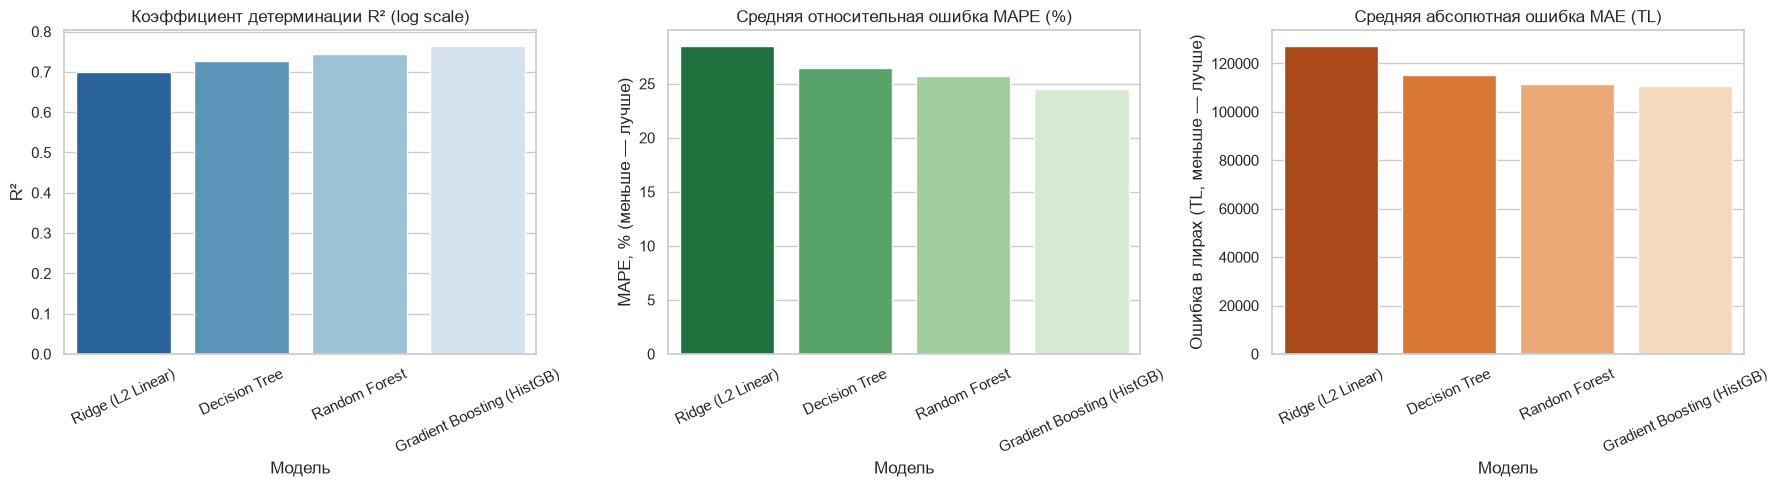

Лучшая модель по метрикам: Gradient Boosting (HistGB)



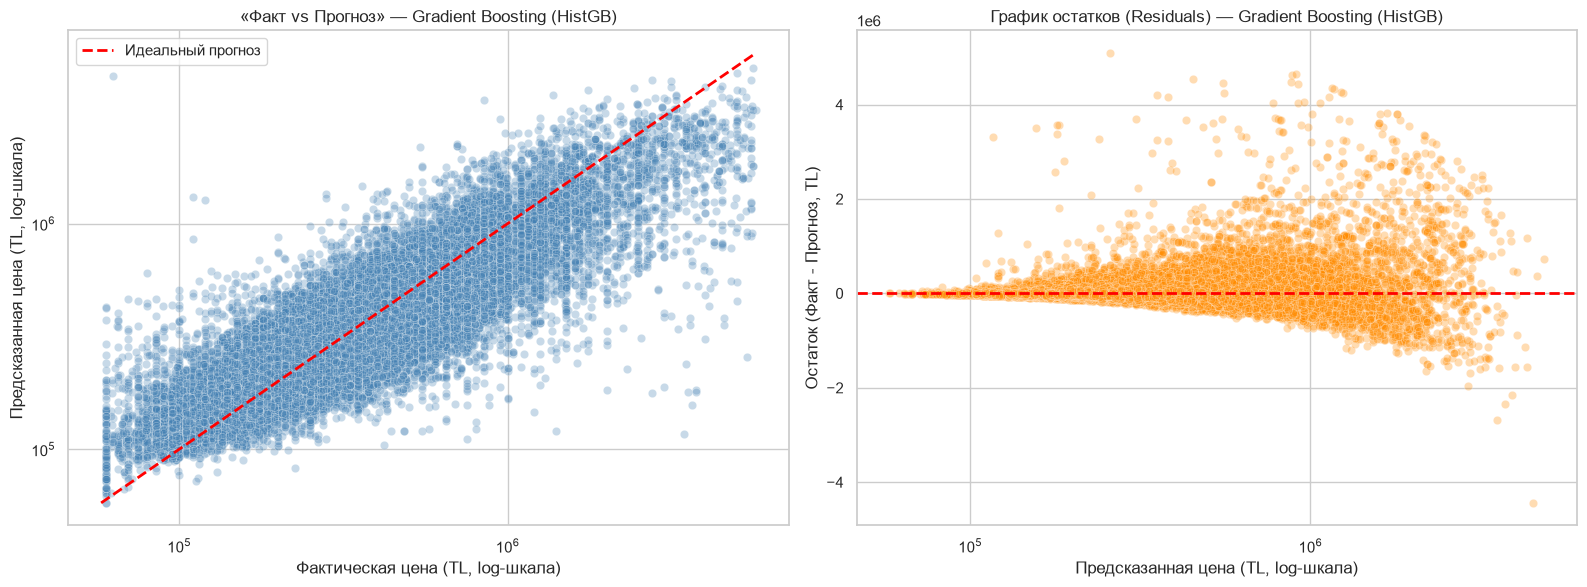

C:\Users\.aorayden\AppData\Local\Temp\ipykernel_7388\2031902531.py:64: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


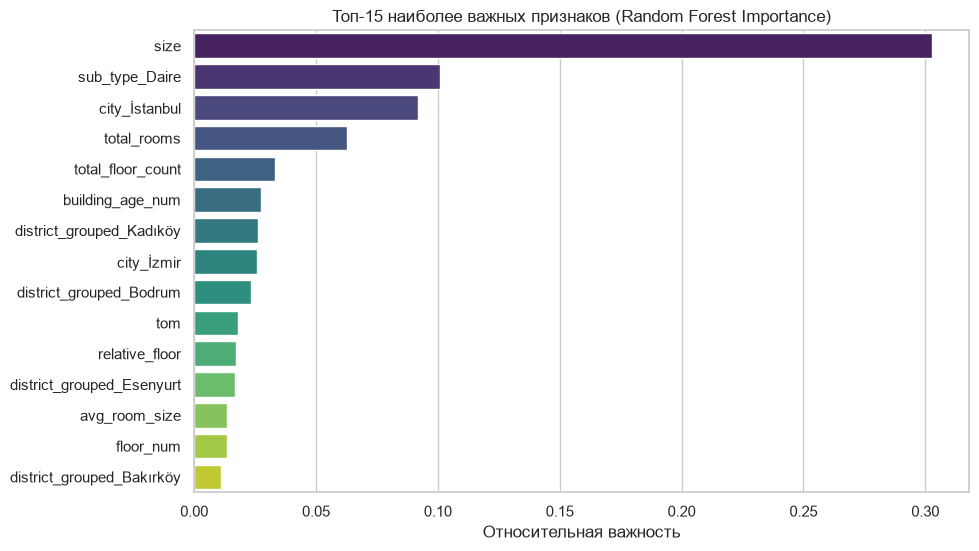

In [14]:
# 1. Столбчатые диаграммы сравнения моделей по метрикам
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Сравнение R²
sns.barplot(x=comparison_df.index, y=comparison_df['R² (log scale)'], ax=axes[0], palette='Blues_r')
axes[0].set_title('Коэффициент детерминации R² (log scale)')
axes[0].set_ylabel('R²')
axes[0].tick_params(axis='x', rotation=25)

# Сравнение MAPE (%)
sns.barplot(x=comparison_df.index, y=comparison_df['MAPE (%)'], ax=axes[1], palette='Greens_r')
axes[1].set_title('Средняя относительная ошибка MAPE (%)')
axes[1].set_ylabel('MAPE, % (меньше — лучше)')
axes[1].tick_params(axis='x', rotation=25)

# Сравнение MAE (TL)
sns.barplot(x=comparison_df.index, y=comparison_df['MAE (TL)'], ax=axes[2], palette='Oranges_r')
axes[2].set_title('Средняя абсолютная ошибка MAE (TL)')
axes[2].set_ylabel('Ошибка в лирах (TL, меньше — лучше)')
axes[2].tick_params(axis='x', rotation=25)

plt.tight_layout()
plt.show()

# 2. Определение модели-победителя (по минимальному MAPE)
best_model_name = comparison_df['MAPE (%)'].idxmin()
best_pred_raw = preds_dict[best_model_name]
print(f"Лучшая модель по метрикам: {best_model_name}\n")

# 3. Графики «Факт vs Прогноз» и «Анализ остатков»
residuals = y_test_true - best_pred_raw

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Факт vs Прогноз (логарифмическая шкала для равномерной визуализации)
sns.scatterplot(x=y_test_true, y=best_pred_raw, alpha=0.3, color='steelblue', ax=axes[0])
min_val = min(y_test_true.min(), best_pred_raw.min())
max_val = max(y_test_true.max(), best_pred_raw.max())
axes[0].plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', lw=2, label='Идеальный прогноз')
axes[0].set_xscale('log')
axes[0].set_yscale('log')
axes[0].set_title(f'«Факт vs Прогноз» — {best_model_name}')
axes[0].set_xlabel('Фактическая цена (TL, log-шкала)')
axes[0].set_ylabel('Предсказанная цена (TL, log-шкала)')
axes[0].legend()

# График остатков
sns.scatterplot(x=best_pred_raw, y=residuals, alpha=0.3, color='darkorange', ax=axes[1])
axes[1].axhline(0, color='red', linestyle='--', lw=2)
axes[1].set_xscale('log')
axes[1].set_title(f'График остатков (Residuals) — {best_model_name}')
axes[1].set_xlabel('Предсказанная цена (TL, log-шкала)')
axes[1].set_ylabel('Остаток (Факт - Прогноз, TL)')

plt.tight_layout()
plt.show()

# 4. Важность признаков (Feature Importance)
# Извлекаем важности из Random Forest
importances = model_rf.feature_importances_
top_indices = np.argsort(importances)[::-1][:15]

plt.figure(figsize=(10, 6))
sns.barplot(
    x=importances[top_indices],
    y=[final_feature_names[i] for i in top_indices],
    palette='viridis'
)
plt.title('Топ-15 наиболее важных признаков (Random Forest Importance)')
plt.xlabel('Относительная важность')
plt.show()

### 3.5 Выбор финальной модели и сериализация в файл (Joblib)

Методологическое обоснование выбора победителя:

1. **Точность:** Градиентный бустинг (`HistGradientBoostingRegressor`) и случайный лес (`RandomForestRegressor`) демонстрируют наименьшие ошибки $\text{MAPE}$ и наибольший $R^2$, превосходя линейную модель и одиночное дерево решений за счет эффективного захвата нелинейных взаимодействий между районом, площадью и планировкой.

2. **Скорость вывода (*Inference time*):** `HistGradientBoostingRegressor` выполняет прогноз за миллисекунды, что идеально подходит для работы веб-приложения / дашборда.

3. **Сериализация:** Для развертывания веб-сервиса сохраняется единый словарь со всеми зависимостями: обученная модель, обученный пайплайн `preprocessor`, список используемых колонок и медианы числовых признаков.

In [15]:
import joblib

# 1. Выбираем победителя
final_model = model_hgb if 'Gradient Boosting' in best_model_name else model_rf

# 2. Упаковываем модель и трансформаторы в единый контейнер
model_artifact = {
    'model': final_model,
    'preprocessor': preprocessor,
    'model_name': best_model_name,
    'final_feature_names': final_feature_names,
    'num_cols': num_cols,
    'cat_cols': cat_cols
}

# 3. Сохранение на диск
model_filename = 'real_estate_model_pipeline.joblib'
joblib.dump(model_artifact, model_filename)
print(f" Модель и препроцессоры успешно сохранены в файл: {model_filename}")

# 4. Проверочная загрузка и тестовый инференс
loaded_artifact = joblib.load(model_filename)
sample_test = X_test.head(1)
sample_prep = loaded_artifact['preprocessor'].transform(sample_test)
sample_pred_log = loaded_artifact['model'].predict(sample_prep)
sample_pred_raw = np.expm1(sample_pred_log[0])

print("\n--- Проверка инференса после загрузки ---")
print(f"Тестовый объект (первая строка теста):\nПлощадь: {sample_test['size'].values[0]} м², Город: {sample_test['city'].values[0]}")
print(f"Предсказанная стоимость: {sample_pred_raw:,.2f} TL")
print(f"Фактическая стоимость:   {y_test_raw.iloc[0]:,.2f} TL")

 Модель и препроцессоры успешно сохранены в файл: real_estate_model_pipeline.joblib

--- Проверка инференса после загрузки ---
Тестовый объект (первая строка теста):
Площадь: 88.0 м², Город: İzmir
Предсказанная стоимость: 390,541.40 TL
Фактическая стоимость:   400,000.00 TL


## Этап 4. Дообучение модели и проверка по заданию

Чернов Илья Дмитриевич, группа 23П-4

Дальше дообучаю уже сохранённый бустинг и прогоняю его по 20 объектам из `test_real_estate_samples.csv`.


### 4.1 Какая модель используется

Брал **HistGradientBoostingRegressor** — градиентный бустинг. 

Модель учится на логарифме цены (`log1p`), а в ответ переводится обратно через `expm1`. Так дорогие объекты меньше перетягивают обучение.

Признаки те же, что при первом обучении: площадь, комнаты, этаж, возраст дома, срок объявления, тип жилья, отопление, город, район. Числа через RobustScaler, категории через one-hot.

На большой тестовой выборке из этого ноутбука у бустинга было примерно: **R² (по логарифму) = 0.76**, **MAE ≈ 110 771 TL**, **MAPE ≈ 24.5%**. В среднем ошибка около 25% от цены.

Дообучение: к готовой модели добавил ещё 15 деревьев (`warm_start`, было 150, стало 165). Шаг обучения для новых деревьев 0.05, чтобы не развалить уже найденные веса. Учил на 10 000 объявлениях о продаже.

На 1500 объектах для проверки до дообучения MAE была **157 371 TL** (R² = 0.209), после — **157 287 TL** (R² = 0.207). Почти одно и то же: модель и так училась на большой выборке, маленькая добавка почти ничего не изменила.


In [ ]:
import re
import numpy as np
import pandas as pd
import joblib

FIO = "Чернов Илья Дмитриевич"
GROUP = "23П-4"

artifact = joblib.load("real_estate_model_pipeline.joblib")
model = artifact["model"]
preprocessor = artifact["preprocessor"]
num_cols = artifact["num_cols"]
cat_cols = artifact["cat_cols"]

ohe = preprocessor.named_transformers_["cat"]
known_districts = set(ohe.categories_[list(cat_cols).index("district_grouped")])

age_mapping = {
    "0": 0, "1": 1, "2": 2, "3": 3, "4": 4, "5": 5,
    "1-5 arası": 3, "6-10 arası": 8, "11-15 arası": 13,
    "16-20 arası": 18, "21 ve üzeri": 25,
}

def parse_rooms(val):
    if pd.isna(val):
        return 2, 1, 3
    m = re.search(r"(\d+)\+(\d+)", str(val))
    if m:
        bed, liv = int(m.group(1)), int(m.group(2))
        return bed, liv, bed + liv
    return 2, 1, 3

def parse_floor(val, total_floors):
    if pd.isna(val):
        return 1
    text = str(val).lower()
    if any(x in text for x in ["zemin", "giriş", "bahçe", "yüksek giriş"]):
        return 0
    if "kot" in text or "bodrum" in text:
        return -1
    m = re.search(r"(-?\d+)", text)
    return int(m.group(1)) if m else 1

def make_features(df):
    data = df.copy()
    data["price"] = pd.to_numeric(data["price"], errors="coerce")
    data["size"] = pd.to_numeric(data["size"], errors="coerce")
    data["tom"] = pd.to_numeric(data["tom"], errors="coerce")
    floors = data["total_floor_count"].astype(str).str.extract(r"(\d+)")[0]
    data["total_floor_count"] = pd.to_numeric(floors, errors="coerce")

    
    data["size"] = data["size"].fillna(data["size"].median()).fillna(90)
    data["tom"] = data["tom"].fillna(30)
    data["total_floor_count"] = data["total_floor_count"].fillna(5)
    data["heating_type"] = data["heating_type"].fillna("Yok")
    data["sub_type"] = data["sub_type"].fillna("Daire")

    rooms = data["room_count"].apply(parse_rooms)
    data["bedrooms"] = [r[0] for r in rooms]
    data["living_rooms"] = [r[1] for r in rooms]
    data["total_rooms"] = [r[2] for r in rooms]
    data["avg_room_size"] = data["size"] / np.maximum(data["total_rooms"], 1)
    data["building_age_num"] = data["building_age"].astype(str).map(age_mapping).fillna(10)
    data["floor_num"] = [parse_floor(f, tf) for f, tf in zip(data["floor_no"], data["total_floor_count"])]
    data["relative_floor"] = np.clip(data["floor_num"] / np.maximum(data["total_floor_count"], 1), -1, 1.5)

    parts = data["address"].fillna("Unknown/Unknown").astype(str).str.split("/")
    data["city"] = parts.apply(lambda x: x[0].strip() if len(x) else "Unknown")
    data["district"] = parts.apply(lambda x: x[1].strip() if len(x) > 1 else "Unknown")
    data["district_grouped"] = data["district"].apply(lambda d: d if d in known_districts else "Other")
    return data

print("сейчас деревьев:", model.n_iter_)


if model.n_iter_ < 165:
    raw = pd.read_csv("real_estate_data.csv", low_memory=False)
    raw = raw[(raw["listing_type"] == 1) & (raw["price_currency"].isin(["TL", "TRY"]))]
    raw["price"] = pd.to_numeric(raw["price"], errors="coerce")
    raw["size"] = pd.to_numeric(raw["size"], errors="coerce")
    raw = raw.dropna(subset=["price", "size"])
    raw = raw[(raw["price"] >= 50000) & (raw["size"] >= 15) & (raw["size"] <= 800)]
    raw = raw.sample(10000, random_state=23)

    extra = make_features(raw)
    X_prep = preprocessor.transform(extra[num_cols + cat_cols])
    y_log = np.log1p(extra["price"].values)

    rng = np.random.RandomState(23)
    idx = rng.permutation(len(X_prep))
    val_idx, fit_idx = idx[:1500], idx[1500:]

    pred_before = np.expm1(model.predict(X_prep[val_idx]))
    y_val = extra["price"].values[val_idx]
    mae_before = np.mean(np.abs(y_val - pred_before))
    r2_before = 1 - np.sum((y_val - pred_before) ** 2) / np.sum((y_val - y_val.mean()) ** 2)
    print(f"до дообучения  MAE {mae_before:.0f}  R2 {r2_before:.3f}")

    model.set_params(warm_start=True, max_iter=int(model.n_iter_) + 15, learning_rate=0.05, early_stopping=False)
    model.fit(X_prep[fit_idx], y_log[fit_idx])

    pred_after = np.expm1(model.predict(X_prep[val_idx]))
    mae_after = np.mean(np.abs(y_val - pred_after))
    r2_after = 1 - np.sum((y_val - pred_after) ** 2) / np.sum((y_val - y_val.mean()) ** 2)
    print(f"после дообучения MAE {mae_after:.0f}  R2 {r2_after:.3f}")
    print("деревьев стало:", model.n_iter_)

    artifact["model"] = model
    joblib.dump(artifact, "real_estate_model_pipeline.joblib")
else:
    print("уже дообучена (150 -> 165 деревьев), повторно не запускаю")

сейчас деревьев: 165
уже дообучена (150 -> 165 деревьев), повторно не запускаю


In [ ]:
test = pd.read_csv("test_real_estate_samples.csv")
test_fe = make_features(test)
pred = np.expm1(model.predict(preprocessor.transform(test_fe[num_cols + cat_cols])))

result = test.copy()
result["ФИО"] = FIO
result["Группа"] = GROUP
result["прогноз_цены"] = np.round(pred, 2)
result.to_csv("result_real_estate_samples.csv", index=False, encoding="utf-8-sig")

show = result[["id", "sub_type", "listing_type", "size", "address", "price", "прогноз_цены"]]
print("сохранил result_real_estate_samples.csv, строк:", len(result))
print(show.to_string(index=False))

сохранил result_real_estate_samples.csv, строк: 20
   id     sub_type  listing_type  size                        address     price  прогноз_цены
   49   Kooperatif             1   1.0        İzmir/Aliağa/Yenişakran  300000.0     179487.87
  506  Çiftlik Evi             1 250.0             İzmir/Foça/Yeniköy 1600000.0    1153304.03
    2        Daire             1  43.0     İstanbul/Kartal/Kordonboyu  490000.0     484470.47
  528 Prefabrik Ev             1 122.0  Tekirdağ/Çerkezköy/Kızılpınar  103600.0      79382.07
  109   Kooperatif             1   1.0        İzmir/Aliağa/Yenişakran  300000.0     177828.62
  100       Yazlık             1 150.0     Mersin/Erdemli/Kargıpınarı  500000.0     435610.67
  320       Yazlık             1 134.0   Balıkesir/Burhaniye/Pelitköy 1000000.0     591994.56
    3        Daire             1   NaN        Tekirdağ/Çorlu/Reşadiye  155000.0     203501.20
 7810         Loft             1 145.0         İzmir/Konak/Akın Simav  650000.0     512985.78
   11  Mü

In [ ]:
y = result["price"].astype(float).values
p = result["прогноз_цены"].astype(float).values
err = y - p
n = len(y)

mae_manual = np.sum(np.abs(err)) / n
rmse_manual = np.sqrt(np.sum(err ** 2) / n)
r2_manual = 1 - np.sum(err ** 2) / np.sum((y - np.mean(y)) ** 2)

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
mae_sk = mean_absolute_error(y, p)
rmse_sk = mean_squared_error(y, p) ** 0.5
r2_sk = r2_score(y, p)

metrics = pd.DataFrame({
    "метрика": ["MAE", "RMSE", "R2"],
    "вручную": [round(mae_manual, 2), round(rmse_manual, 2), round(r2_manual, 4)],
    "sklearn": [round(mae_sk, 2), round(rmse_sk, 2), round(r2_sk, 4)],
})
print(metrics.to_string(index=False))

sale = result["listing_type"].values == 1
y_s, p_s = y[sale], p[sale]
err_s = y_s - p_s
print()
print("только продажа, объектов:", sale.sum())
print("MAE ", round(np.sum(np.abs(err_s)) / len(y_s), 2))
print("RMSE", round(np.sqrt(np.sum(err_s ** 2) / len(y_s)), 2))
print("R2  ", round(1 - np.sum(err_s ** 2) / np.sum((y_s - y_s.mean()) ** 2), 4))

метрика     вручную     sklearn
    MAE 560504.2600 560504.2600
   RMSE 758818.8500 758818.8500
     R2     -0.4783     -0.4783

только продажа, объектов: 10
MAE  264102.62
RMSE 449334.11
R2   0.5955


### 4.2 Что получилось на 20 объектах

Прогноз лежит в `result_real_estate_samples.csv`. 

Метрики по всем 20 строкам (ручной расчёт и sklearn совпали):

| метрика | вручную | sklearn |
|---|---:|---:|
| MAE | 560504.26 | 560504.26 |
| RMSE | 758818.85 | 758818.85 |
| R² | -0.4783 | -0.4783 |

Формулы обычные: MAE — среднее модуля ошибки, RMSE — корень из среднего квадрата ошибки, R² = 1 − SS_res / SS_tot.

**Разбор.** Общий R² отрицательный, и MAE больше полумиллиона лир. Так вышло не потому, что модель на всех квартирах «не работает». В файле 10 продаж и 10 аренд. Модель училась только на продаже. Аренда стоит 750–19 000, а прогноз выходит на сотни тысяч. Эти 10 строк и ломают общие метрики.

Если оставить только продажу:

- MAE ≈ 264 103 
- RMSE ≈ 449 334 
- R² ≈ 0.60

RMSE больше MAE, потому что есть несколько сильных промахов, а квадрат ошибки их раздувает.

Где промах большой:
- аренда;
- пустая площадь, её заполнил медианой;
- дорогие редкие дома, например дом в Бодруме за 2.45 млн, прогноз около 1.19 млн.

